# Part 0: Environment Setup

Import Library

In [82]:
%matplotlib inline
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pickle

print("✅ All libraries loaded!")

✅ All libraries loaded!


In [83]:
# ── Read requirements.txt — line by line ─────────────────────────────────────
packages = {}
print("Packages required for SIT3020:")
with open(r"requirements.txt", "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line and not line.startswith("#"):
            print(f"  📦 {line}")
            if ">=" in line:
                pkg, ver = line.split(">=")
                packages[pkg] = ver
            else:
                packages[line] = "0.0.0" # Default minimum version if not specified

Packages required for SIT3020:
  📦 numpy>=1.23.0
  📦 pandas>=1.5.0
  📦 matplotlib>=3.6.0
  📦 scipy>=1.9.0
  📦 seaborn>=0.13.2
  📦 scikit-learn>=1.2.0
  📦 mglearn>=0.1.9
  📦 imbalanced-learn>=0.12.0
  📦 openpyxl>=3.0.10
  📦 pyarrow>=10.0.0
  📦 jupyter>=1.0.0
  📦 ipykernel>=6.0.0


In [84]:
for pkg, min_ver in packages.items():
    try:
        mod = __import__(pkg)
        ver = getattr(mod, "__version__", "?")
        ok  = "✅" if ver >= min_ver else "⚠️  version too old"
        print(f"  {ok}  {pkg:12s}  version: {ver}")
    except ImportError:
        print(f"  ❌  {pkg:12s}  NOT FOUND — run: pip install {pkg}")

  ✅  numpy         version: 2.5.4
  ✅  pandas        version: 3.0.6
  ⚠️  version too old  matplotlib    version: 3.11.2
  ⚠️  version too old  scipy         version: 1.18.1
  ✅  seaborn       version: 0.13.2
  ❌  scikit-learn  NOT FOUND — run: pip install scikit-learn
  ✅  mglearn       version: 0.1.9
  ❌  imbalanced-learn  NOT FOUND — run: pip install imbalanced-learn
  ✅  openpyxl      version: 3.1.5
  ✅  pyarrow       version: 26.0.0
  ✅  jupyter       version: ?
  ✅  ipykernel     version: 7.4.0


# Part 1: Data Cleaning

1a. Load the dataset and display the first five rows. Drop the identifiers columns. Display the updated shape and confirm the correct number of remaining columns.

In [85]:
# ── Load earthquake.csv — the main dataset
df = pd.read_csv(
    "earthquake.csv",
    na_values=["N/A","--",""],      # treat these as NaN
)

# Display the first five rows
print(f"Loaded: {df.shape[0]} rows × {df.shape[1]} columns")
print(df.head())

Loaded: 1000 rows × 19 columns
                                      title  magnitude         date_time  cdi  \
0          M 6.5 - 42 km W of Sola, Vanuatu        6.5  16-08-2023 12:47    7   
1  M 6.5 - 43 km S of Intipucá, El Salvador        6.5  19-07-2023 00:22    8   
2  M 6.6 - 25 km ESE of Loncopué, Argentina        6.6  17-07-2023 03:05    7   
3     M 7.2 - 98 km S of Sand Point, Alaska        7.2  16-07-2023 06:48    6   
4                  M 7.3 - Alaska Peninsula        7.3  16-07-2023 06:48    0   

   mmi   alert  tsunami  sig net  nst      dmin    gap magType    depth  \
0    4   green        0  657  us  114  7.177000   25.0     mww  192.955   
1    6  yellow        0  775  us   92  0.679000   40.0     mww   69.727   
2    5   green        0  899  us   70  1.634000   28.0     mww  171.371   
3    6   green        1  860  us  173  0.907000   36.0     mww   32.571   
4    5     NaN        1  820  at   79  0.879451  172.8      Mi   21.000   

   latitude  longitude         

In [86]:
# Drop the identifier columns
# 'title' is dropped here because it is a unique text string for each event,
# not a measurable feature or category.
df.drop(columns=['title'], inplace=True)

In [87]:
# Handle data type, formatting
df['date_time'] = pd.to_datetime(df['date_time'], format='%d-%m-%Y %H:%M', errors='coerce')
df['year'] = df['date_time'].dt.year

# Confirm conversion
print(f"Date range: {df['year'].min()} to {df['year'].max()}")

Date range: 1995 to 2023


In [88]:
# Display the updated shape and confirm remaining columns
print("\n--- Updated Dataset Info ---")
print(f"Updated Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Remaining Columns:\n{df.columns.tolist()}")


--- Updated Dataset Info ---
Updated Shape: 1000 rows × 19 columns
Remaining Columns:
['magnitude', 'date_time', 'cdi', 'mmi', 'alert', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'gap', 'magType', 'depth', 'latitude', 'longitude', 'location', 'continent', 'country', 'year']


1b. Check for missing values across all remaining columns. Report the count and
percentage of missing values for each affected column. For alert and continent,
explain why these columns cannot be reliably imputed or used as features in
this dataset despite being potentially informative.

In [89]:
# Check for missing values across all remaining columns
print("Missing values:")
missing = pd.DataFrame({
    "count": df.isnull().sum(),
    "pct(%)": (df.isnull().mean()*100).round(2)
})
# Filter to show only columns that actually have missing values
print(missing[missing["count"]>0])

Missing values:
           count  pct(%)
alert        551    55.1
location       6     0.6
continent    716    71.6
country      349    34.9


Why alert and continent cannot be reliably imputed:

alert: Alert levels (e.g., green, yellow) are specific warnings issued by agencies like the U.S. Geological Survey (USGS) based on estimated fatalities and economic damage. They are usually only issued for significant events. We cannot simply guess or mathematically calculate (impute) an alert level using mean or mode, because it is a complex administrative label, not a natural measurement. Imputing a "green" alert for a missing value might falsely suggest an agency assessed it as safe, when in reality, they simply never assessed it at all.

continent: Earthquake locations are tied to strict geospatial coordinates (latitude and longitude). Standard statistical imputation (like filling missing values with the most frequent continent) would place earthquakes in geographically impossible locations. Furthermore, many major earthquakes happen in the ocean along tectonic fault lines (like the Pacific Ring of Fire), meaning they don't belong to any continent. Therefore, missing continent data is often "missing by design" and cannot be reliably faked.

1c. Display the number of earthquake records per country (for non-missing values
only). Identify the top five countries with the most recorded major earthquakes.
Based on your geographic knowledge, suggest what these countries have in
common in terms of tectonic plate activity. cohort?

In [90]:
# 1c. Display the number of earthquake records per country (non-missing only)
print("--- Number of Earthquake Records per Country ---")
# value_counts() automatically excludes missing (NaN) values
country_counts = df['country'].value_counts()
display(country_counts)

# Identify the top five countries with the most recorded major earthquakes
print("\n--- Top 5 Countries with Major Earthquakes ---")
top_5_major_countries = country_counts.head(5)
display(top_5_major_countries)

--- Number of Earthquake Records per Country ---


country
Indonesia                                                     140
Papua New Guinea                                               81
Chile                                                          42
Vanuatu                                                        36
Mexico                                                         31
Peru                                                           26
Japan                                                          26
Solomon Islands                                                25
United States of America                                       24
Philippines                                                    23
Russia                                                         19
People's Republic of China                                     15
Afghanistan                                                    10
Ecuador                                                        10
Fiji                                                           10
Ta


--- Top 5 Countries with Major Earthquakes ---


country
Indonesia           140
Papua New Guinea     81
Chile                42
Vanuatu              36
Mexico               31
Name: count, dtype: int64

Based on the data, the top five countries with the most major earthquakes are **Indonesia, Papua New Guinea, Chile, Vanuatu, **and** Mexico**. Geographically and geologically, these nations share a few major commonalities:


*   The Pacific Ring of Fire: All five of these countries are located along the margins of the Pacific Ocean within the "Ring of Fire," a massive, horseshoe-shaped seismically active belt that experiences about 90% of the world's earthquakes.
*   Convergent Plate Boundaries (Subduction Zones): More specifically, these countries all sit on or immediately adjacent to incredibly active subduction zones. This is a type of tectonic plate boundary where plates collide, and a denser oceanic plate is actively being thrust underneath another plate into the Earth's mantle. For example, Chile and Mexico sit where oceanic plates (the Nazca and Cocos plates) are forced under the Americas. Indonesia, Papua New Guinea, and Vanuatu sit on complex collision zones involving the massive Pacific and Indo-Australian plates.
*   Massive Energy Release: Because subduction zones involve immense pressure and friction, the plates frequently get "stuck." When the stress finally overcomes the friction, it triggers a massive release of energy. This explains not only the high frequency of earthquakes in these five countries but also their extreme severity.

# Part 2: Exploratory Data Analysis

## 2a. Descriptive Statistics

i. Generate descriptive statistics (count, mean, standard deviation, min, and max) for the following numerical features: magnitude, cdi, mmi, sig, nst, dmin, gap, and depth. Identify the feature with the highest standard deviation relative to its mean (coefficient of variation) and comment on what high variability in that feature suggests about the diversity of earthquake events in the dataset.

In [91]:
# Descriptive Statistics
features = ['magnitude', 'cdi', 'mmi', 'sig', 'nst', 'dmin', 'gap', 'depth']

# Generate standard descriptive stats
desc_stats = df[features].agg(['count', 'mean', 'std', 'min', 'max']).T

# Calculate the Coefficient of Variation (CV = std / mean)
desc_stats['CV'] = desc_stats['std'] / desc_stats['mean']

print("--- Descriptive Statistics & Coefficient of Variation ---")
# Display sorted by CV to easily identify the highest
display(desc_stats.sort_values(by='CV', ascending=False))

highest_cv_feature = desc_stats['CV'].idxmax()
highest_cv_value = desc_stats['CV'].max()
print(f"\nFeature with highest CV: **{highest_cv_feature}** (CV = {highest_cv_value:.2f})")

--- Descriptive Statistics & Coefficient of Variation ---


,count,mean,std,min,max,CV
dmin,1000.0,1.125174,2.073164,0.0,17.654,1.842527
depth,1000.0,74.612541,130.812590,2.7,670.810,1.753225
nst,1000.0,193.918000,239.045858,0.0,934.000,1.232716
gap,1000.0,20.926290,24.415895,0.0,239.000,1.166757
cdi,1000.0,3.605000,3.328972,0.0,9.000,0.923432
sig,1000.0,847.915000,301.802632,650.0,2910.000,0.355935
mmi,1000.0,6.027000,1.433990,1.0,10.000,0.237928
magnitude,1000.0,6.940150,0.438148,6.5,9.100,0.063132



Feature with highest CV: **dmin** (CV = 1.84)


**Key Descriptive Statistics:**
* **Central Tendency & Spread:** The `magnitude` feature has a mean of 6.94, with a relatively low standard deviation of 0.438, meaning most earthquakes in this dataset are tightly clustered around the high 6s to low 7s.
* **High Variability:** In contrast, `depth` has a mean of 74.61 km but a massive standard deviation of 130.81 km. The gap between the 75th percentile (55 km) and the max (670.81 km) indicates the presence of extreme deep-focus earthquake outliers.

The feature with the highest coefficient of variation is **dmin (the distance to the nearest seismic station)**. This extremely high variability suggests that the earthquakes in this dataset occur across wildly diverse geographic settings with unequal monitoring capabilities. Quakes in regions with dense seismic networks (like Japan or California) will have a near-zero dmin, while earthquakes occurring in remote areas, such as the middle of the Pacific Ocean, will have a massive dmin because the nearest sensor is hundreds of miles away.

ii. Compare the mean values of magnitude, depth, cdi, and dmin between tsunami
events (tsunami = 1) and non-tsunami events (tsunami = 0) using groupby. For
each variable, state whether the mean is higher for tsunami or non-tsunami
events and write one sentence interpreting what the difference (or lack of
difference) suggests physically.

In [92]:
# Compare mean values between tsunami and non-tsunami events
features_to_compare = ['magnitude', 'depth', 'cdi', 'dmin']

print("--- Mean Values by Tsunami Event (0 = No, 1 = Yes) ---")
tsunami_means = df.groupby('tsunami')[features_to_compare].mean()
display(tsunami_means)

--- Mean Values by Tsunami Event (0 = No, 1 = Yes) ---


,magnitude,depth,cdi,dmin
tsunami,,,,
0,6.940519,68.197874,2.930370,0.487960
1,6.939385,87.935311,5.006154,2.448619


**Interpretation of Mean Differences of Tsunami vs. Non-Tsunami Events**



*   magnitude: The mean magnitude is nearly identical, though technically slightly lower for tsunami events (6.939 vs. 6.940).

Because this dataset already consists mostly of very strong earthquakes, sheer magnitude alone does not strongly differentiate tsunami generation here; other factors like the specific fault mechanism or ocean floor displacement are likely more critical.


*  depth: The mean depth is higher (deeper) for tsunami events (87.9 km vs. 68.2 km).

While tsunamis are often associated with shallow quakes, this specific dataset implies that the tsunami-generating earthquakes recorded here occurred deeper within subduction zones, potentially displacing massive tectonic blocks or triggering secondary submarine landslides.


*   cdi (Community Internet Intensity Map): The mean CDI is significantly higher for tsunami events (5.01 vs. 2.93).

Tsunami events cause widespread coastal threats and generate high public awareness and alarm, leading to a much higher volume of community intensity reports being submitted online.

*   dmin (Distance to nearest station): The mean dmin is significantly higher for tsunami events (2.45 vs. 0.49).

Tsunamis are inherently generated by offshore earthquakes in the ocean, meaning their epicenters are naturally much farther away from land-based seismic monitoring stations compared to terrestrial quakes.

iii. Classify earthquakes by depth into three categories: Shallow (< 70 km),
Intermediate (70–300 km), and Deep (> 300 km). Add this as a new column
called depth_category. Report the count and percentage of events in each
category. Then calculate the tsunami rate (proportion of tsunami = 1) for each
depth category and comment on the relationship between depth and tsunami
occurrence

In [93]:
# Classify by depth and calculate tsunami rates
# Re-applying to ensure strict boundaries: Shallow (< 70), Intermediate (70-300), Deep (> 300)
df['depth_category'] = pd.cut(
    df['depth'],
    bins=[0, 70, 300, np.inf],
    labels=['Shallow', 'Intermediate', 'Deep'],
    right=False # Ensures the bin is [0, 70), meaning strictly less than 70
)

# Calculate Count and Percentage
depth_stats = pd.DataFrame({
    'Count': df['depth_category'].value_counts(sort=False),
    'Percentage (%)': (df['depth_category'].value_counts(normalize=True, sort=False) * 100).round(2)
})

print("--- Earthquake Count and Percentage by Depth ---")
display(depth_stats)

# Calculate Tsunami Rate (proportion of tsunami = 1)
# Converting the tsunami column to int temporarily for the mean calculation
tsunami_rate = df.assign(
    tsunami_numeric=df['tsunami'].astype(int)
).groupby('depth_category', observed=False)['tsunami_numeric'].mean().reset_index()

tsunami_rate.columns = ['Depth Category', 'Tsunami Rate (Proportion)']
tsunami_rate['Tsunami Rate (%)'] = (tsunami_rate['Tsunami Rate (Proportion)'] * 100).round(2)

print("\n--- Tsunami Rate by Depth Category ---")
display(tsunami_rate)

--- Earthquake Count and Percentage by Depth ---


,Count,Percentage (%)
depth_category,,
Shallow,787,78.7
Intermediate,155,15.5
Deep,58,5.8



--- Tsunami Rate by Depth Category ---


,Depth Category,Tsunami Rate (Proportion),Tsunami Rate (%)
0,Shallow,0.312579,31.26
1,Intermediate,0.335484,33.55
2,Deep,0.465517,46.55


**Relationship Between Depth and Tsunami Occurrence**

Based on the data, the vast majority of earthquakes occur in the Shallow category (78.7%). However, counterintuitively, the highest proportion of tsunami events occurs within the Deep category (46.55%), followed by Intermediate (33.55%) and then Shallow (31.26%).

There are two primary reasons for this unexpected relationship in this specific dataset:



*  Sample Size and Selection Bias: There are very few deep earthquakes in this dataset (only 58 out of 1000). With such a small sample size, just a handful of positive tsunami flags will drastically inflate the percentage. Furthermore, because this dataset only contains relatively large earthquakes (magnitude 6.5+), any deep earthquake recorded here is a massive seismic event.

*   Massive deep-focus earthquakes (especially in subduction zones) are automatically and heavily evaluated by warning centers. While deep earthquakes are too far down to directly displace the seafloor, their massive energy can trigger secondary events, such as massive underwater landslides, which then generate tsunamis.

## 2b. Data Visualisation

i. Plot a histogram of magnitude. Describe the shape of the distribution and
identify the most common magnitude range in this dataset. Note that all events
have a magnitude of at least 6.5, comment on what this implies about the
sampling strategy used to collect the data.

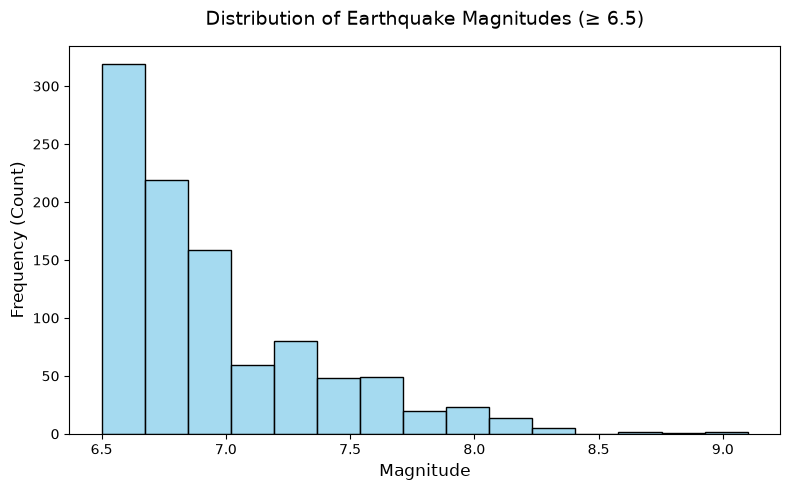

In [94]:
# Configurable variables for the plot
fig_width = 8
fig_height = 5
num_bins = 15
hist_color = 'skyblue'

# Create the figure
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Plot the histogram for magnitude
sns.histplot(data=df, x='magnitude', bins=num_bins, color=hist_color, edgecolor='black', kde=False, ax=ax)

# Add titles and labels
ax.set_title('Distribution of Earthquake Magnitudes (≥ 6.5)', fontsize=14, pad=15)
ax.set_xlabel('Magnitude', fontsize=12)
ax.set_ylabel('Frequency (Count)', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

The histogram displays a strongly right-skewed distribution which indicates it is positively skewed. The frequency of earthquakes drops off rapidly and almost exponentially as the magnitude increases, leaving a long right tail for the rarest and most extreme events, where the magnitude is 8.0 and above. The most common magnitude range in this dataset is represented by the tallest bar on the far left, which falls between 6.5 and approximately 6.7.

The fact that all events have a magnitude of at least 6.5 implies a purposive and threshold-based sampling strategy. The data was intentionally filtered to exclude the millions of minor, everyday tremors that occur globally. By establishing a strict cutoff at 6.5, the agency focused exclusively on major, potentially destructive seismic events. This approach is highly appropriate for our analysis, as low-magnitude earthquakes generally lack the energy required to trigger a tsunami or cause significant global impact.

ii. Create a boxplot of depth grouped by tsunami (x-axis: tsunami status, y-axis:
depth). Describe the difference in depth distribution between tsunami and nontsunami events. Based on the physical mechanism of tsunami generation,
explain whether shallow or deep earthquakes are more likely to trigger a
tsunami and whether your boxplot is consistent with this expectation.

C:\Users\lookhaiming\AppData\Local\Temp\ipykernel_7584\1111736332.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='tsunami_label', y='depth', palette=box_palette, ax=ax)


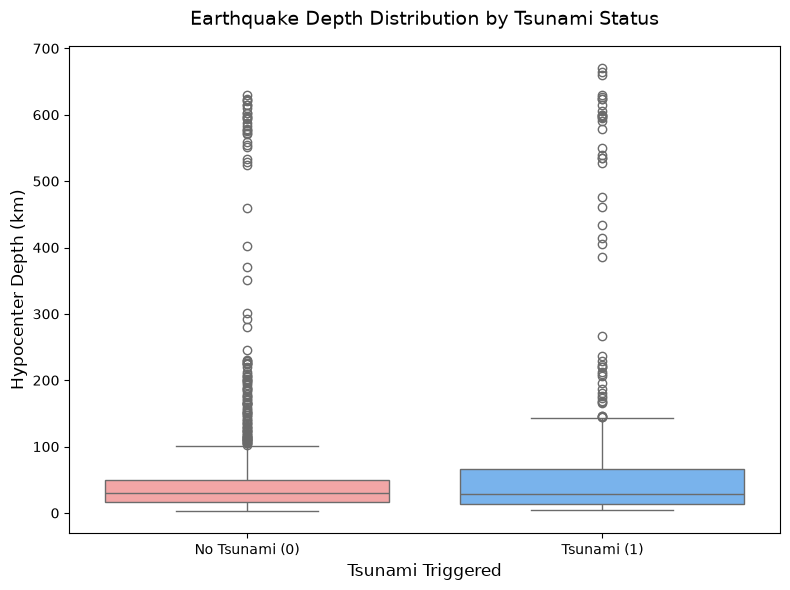

In [95]:
# Configurable variables for the plot
fig_width = 8
fig_height = 6
box_palette = ['#ff9999', '#66b3ff'] # Colors for 0 (No Tsunami) and 1 (Tsunami)

# Create the figure
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Create a temporary column for clearer x-axis labels
df['tsunami_label'] = df['tsunami'].map({0: 'No Tsunami (0)', 1: 'Tsunami (1)'})

# Plot the boxplot
sns.boxplot(data=df, x='tsunami_label', y='depth', palette=box_palette, ax=ax)

# Add titles and labels
ax.set_title('Earthquake Depth Distribution by Tsunami Status', fontsize=14, pad=15)
ax.set_xlabel('Tsunami Triggered', fontsize=12)
ax.set_ylabel('Hypocenter Depth (km)', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

# Drop the temporary label column to keep the dataframe clean
df.drop(columns=['tsunami_label'], inplace=True)

The boxplot shows that both tsunami and non-tsunami events are heavily concentrated at shallow depths, with their medians resting near 30 km. However, the "Tsunami (1)" group has a slightly wider Interquartile Range and a higher upper whisker compared to the "No Tsunami (0)" group. Notably, both categories feature a long tail of deep-earthquake outliers extending well past 600 km.

Physically, a tsunami is generated when an earthquake causes a sudden and significant vertical displacement of the ocean floor, which in turn pushes the massive column of water above it. Because of this, shallow earthquakes are far more likely to trigger tsunamis. Deep earthquakes, which usually has a depth of at least 300 km, dissipate their energy deep within the Earth's mantle and generally do not cause the surface crustal ruptures necessary to displace the seafloor.

The boxplot is consistent with this physical expectation. The core bulk of the tsunami data sits firmly in the shallow depth zone, which is less than 70 km. Even though there are some deep outliers associated with tsunamis in this dataset, the heavy concentration of the distribution at the bottom of the y-axis confirms that shallow depths are a primary characteristic of tsunami-triggering earthquakes. Additionally, these outliers may also be due to secondary triggers like underwater landslides.

iii. Plot a scatter plot of latitude (x-axis) versus longitude (y-axis), with each point
coloured by tsunami (1 = tsunami, 0 = no tsunami) and sized by magnitude.
Describe the geographic clustering of events you observe. Identify at least two
geographic regions where tsunami-generating earthquakes appear to be
concentrated and name the tectonic feature (e.g. subduction zone or fault)
associated with each region.

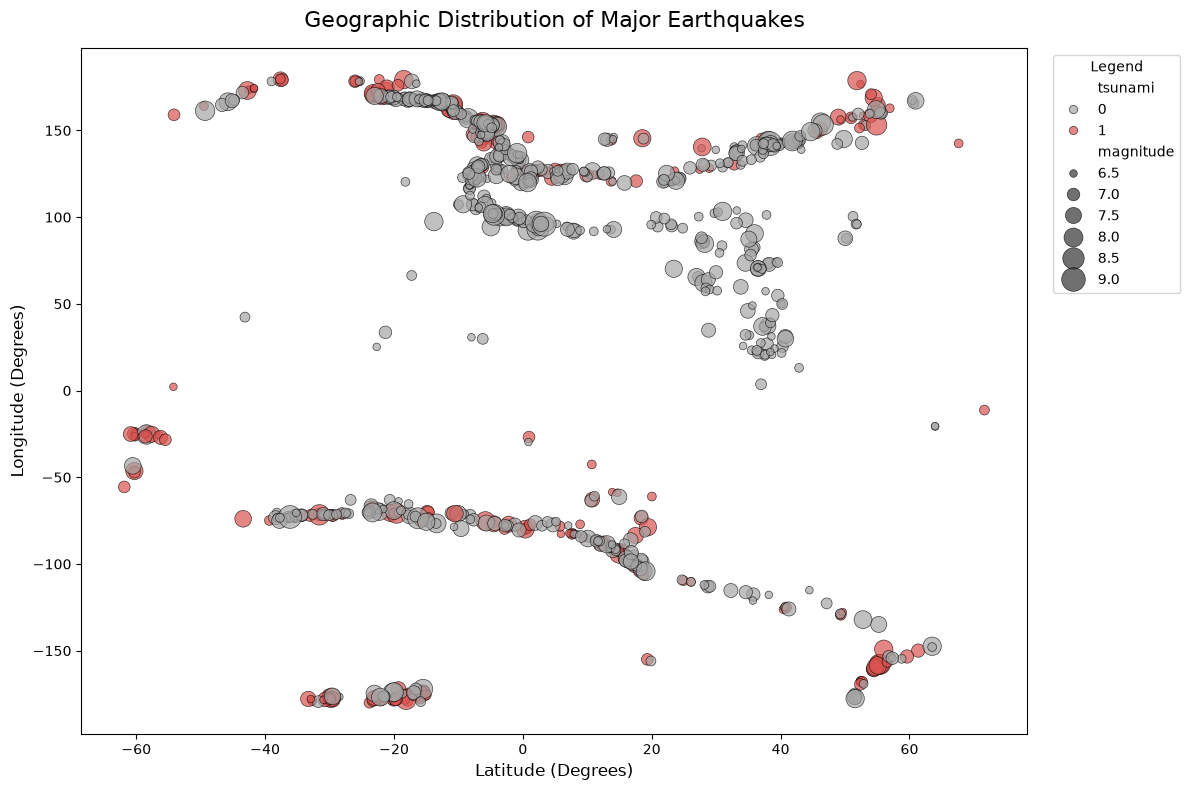

In [96]:
# Configurable variables for the plot
fig_width = 12
fig_height = 8
point_alpha = 0.7
min_dot_size = 30
max_dot_size = 300

# Set up the figure
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Create the scatter plot with x=latitude and y=longitude.
sns.scatterplot(
    data=df,
    x='latitude',
    y='longitude',
    hue='tsunami',
    size='magnitude',
    sizes=(min_dot_size, max_dot_size),
    alpha=point_alpha,
    palette=['#a6a6a6', '#d9534f'], # Grey for No Tsunami (0), Red for Tsunami (1)
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

# Add titles and labels
ax.set_title('Geographic Distribution of Major Earthquakes', fontsize=16, pad=15)
ax.set_xlabel('Latitude (Degrees)', fontsize=12)
ax.set_ylabel('Longitude (Degrees)', fontsize=12)

# Move the legend outside the plot so it doesn't cover the data points
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Legend')

# Display the plot
plt.tight_layout()
plt.show()

Geographic Clustering:

The scatter plot demonstrates that major earthquakes are not randomly distributed across the globe. Instead, they form highly concentrated, distinct linear bands and curved arcs. These clusters perfectly trace the outlines of the Earth's major tectonic plate boundaries. The most prominent shape visible in the data is the circum-Pacific belt, commonly known as the "Ring of Fire," where the vast majority of tsunami-generating events are concentrated.


Based on the coordinate clusters, we can identify two heavily concentrated regions for tsunami-generating earthquakes:

Region 1: West Coast of South America (Chile and Peru)

* Coordinates on plot:

   Latitude ~ -40° to 0°, Longitude ~ -70° to -80°

* Tectonic Feature: The Peru-Chile Trench (Subduction Zone)

  This region is highly active because the oceanic Nazca Plate is continually subducting beneath the continental South American Plate, generating massive megathrust earthquakes that displace the ocean floor.

Region 2: Japan and the Northwestern Pacific

* Coordinates on plot:

  Latitude ~ 30° to 50°, Longitude ~ 140° to 150°
    
* Tectonic Feature: The Japan Trench / Kuril-Kamchatka Trench (Subduction Zones)

  Here, the dense Pacific Plate dives beneath the lighter plates (Okhotsk/North American). The sudden release of tension along these shallow megathrust faults frequently triggers severe tsunamis.

## 2c. Point-Biserial Correlation

i. Use Point-Biserial correlation to compute the correlation between each seismic
feature and the binary target tsunami. Present the results as a table showing
the correlation coefficient (r) and p-value for each feature. Sort by absolute r
value in descending order and indicate which results are statistically significant (p < 0.05).

In [97]:
# Use Point-Biserial correlation to compute the correlation between each seismic feature and the binary target tsunami
# define seismic features and binary target
seismic_features = ['magnitude', 'depth', 'sig', 'cdi', 'mmi',
                    'nst', 'dmin', 'gap']

binary_target = df['tsunami']

results = []

# loop through each features and extract the correlation results (p-value and r)
for feature in seismic_features:
    r, p = stats.pointbiserialr(df[feature], binary_target)
    results.append({
        'Feature'     : feature,
        'r'           : round(r, 4),
        'p-value'     : round(p, 4),
        'Significant' : 'Yes' if p < 0.05 else 'No'
    })

# Sort by absolute r value (strongest first)
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='r', key=abs, ascending=False)
results_df = results_df.reset_index(drop=True)
results_df.index += 1

print("Point-Biserial Correlation — Seismic Features vs Tsunami")
print(results_df.to_string())

Point-Biserial Correlation — Seismic Features vs Tsunami
     Feature       r  p-value Significant
1       dmin  0.4432   0.0000         Yes
2        nst -0.4260   0.0000         Yes
3        cdi  0.2922   0.0000         Yes
4        gap  0.2363   0.0000         Yes
5        mmi -0.1754   0.0000         Yes
6      depth  0.0707   0.0254         Yes
7        sig  0.0248   0.4325          No
8  magnitude -0.0012   0.9694          No


The seismic features that are statistically significant are dmin, nst, cdi, gap, mmi and depth.

ii. Visualise the Point-Biserial correlation coefficients as a horizontal bar chart.
Note that magnitude will show near-zero correlation with tsunami. Explain the
physical reason why a high-magnitude earthquake does NOT automatically
trigger a tsunami, state at least two additional physical conditions that must be
present and identify the two features with the strongest absolute association
with tsunami occurrence.

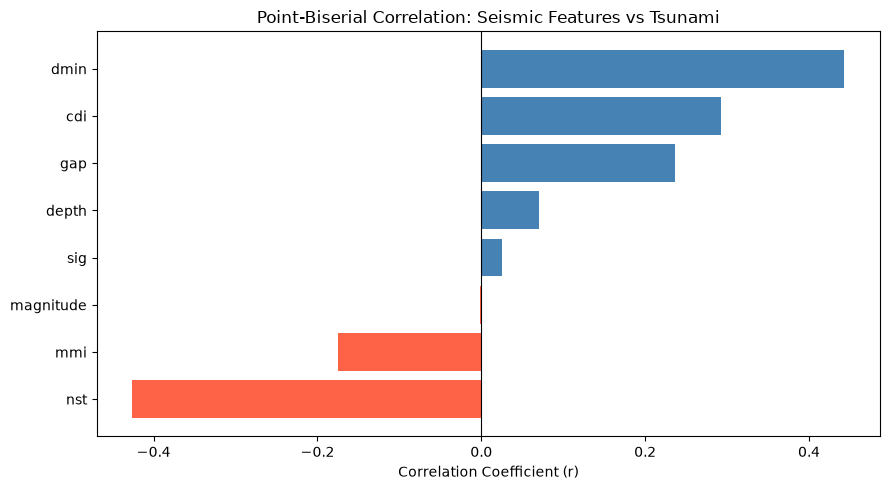

In [98]:
# Visualise the Point-Biserial correlation coefficients as a horizontal bar chart
chart_df = results_df.sort_values('r')

colors = ['steelblue' if r > 0 else 'tomato' for r in chart_df['r']]

plt.figure(figsize=(9, 5))
plt.barh(chart_df['Feature'], chart_df['r'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation Coefficient (r)')
plt.title('Point-Biserial Correlation: Seismic Features vs Tsunami')
plt.tight_layout()
plt.show()

iii. Why does high magnitude NOT automatically trigger a tsunami?

Magnitude measures the total energy released by an earthquake,
but energy alone does not move ocean water. A tsunami only forms
when the seafloor is displaced vertically, pushing the water
column above it.

Two additional physical conditions that must be present:
  1. The earthquake must occur underneath or near the ocean coast.
     A large earthquake on land (e.g. in a desert or mountain
     range) cannot displace ocean water.

  2. The fault movement must be VERTICAL (dip-slip fault).
     If the fault slides horizontally (strike-slip), it does not
     lift the seafloor enough to generate a tsunami wave.

That is why magnitude alone is a weak predictor where it only tells
us how much energy was released, not WHERE or HOW the ground moved.

In [99]:
# two features with the strongest absolute association with tsunami occurrence.
top2 = results_df.head(2)
print("Two features with the strongest association with tsunami:")
print(f"  1. {top2.iloc[0]['Feature']}  (r = {top2.iloc[0]['r']})")
print(f"  2. {top2.iloc[1]['Feature']}  (r = {top2.iloc[1]['r']})")

Two features with the strongest association with tsunami:
  1. dmin  (r = 0.4432)
  2. nst  (r = -0.426)


## 2d. Data Skewness

In [100]:
# Check the distribution shape via Skewness
print("--- Skewness of Numerical Features ---")
print("Values > 1 or < -1 indicate a highly skewed distribution.")
numeric_cols = ['magnitude', 'depth', 'sig', 'cdi', 'mmi', 'nst', 'dmin', 'gap']
skewness = df[numeric_cols].skew().sort_values(ascending=False)
display(pd.DataFrame({'Skewness': skewness}))

--- Skewness of Numerical Features ---
Values > 1 or < -1 indicate a highly skewed distribution.


,Skewness
gap,4.189030
sig,3.461192
depth,3.151106
dmin,2.816674
magnitude,1.368719
nst,0.805896
cdi,0.155289
mmi,-0.265796


**Distribution Shape Analysis:**

The skewness calculation numerically confirms the shape of our data distributions. Features like `gap` (4.18), `sig` (3.46), `depth` (3.15), and `dmin` (2.81) exhibit severe positive (right) skewness. This means their distributions are not symmetrical (bell-shaped) but instead have a long tail stretching towards higher, extreme values.

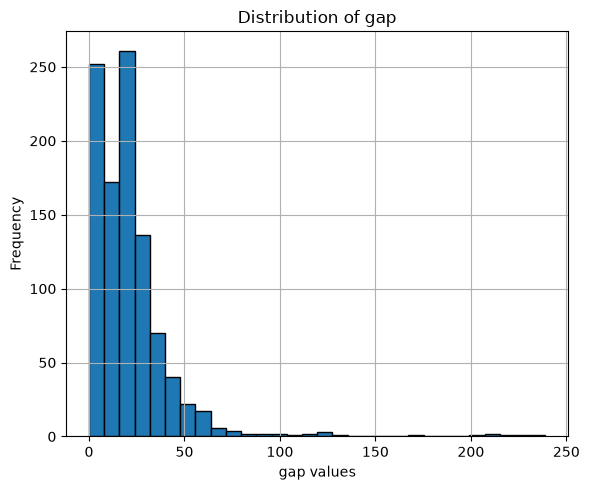

In [101]:
# Create a figure and a set of subplots for 'gap'
fig_gap, ax_gap = plt.subplots(1, 1, figsize=(6, 5))

# Plot histogram for 'gap'
df['gap'].hist(ax=ax_gap, bins=30, edgecolor='black')
ax_gap.set_title('Distribution of gap')
ax_gap.set_xlabel('gap values')
ax_gap.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

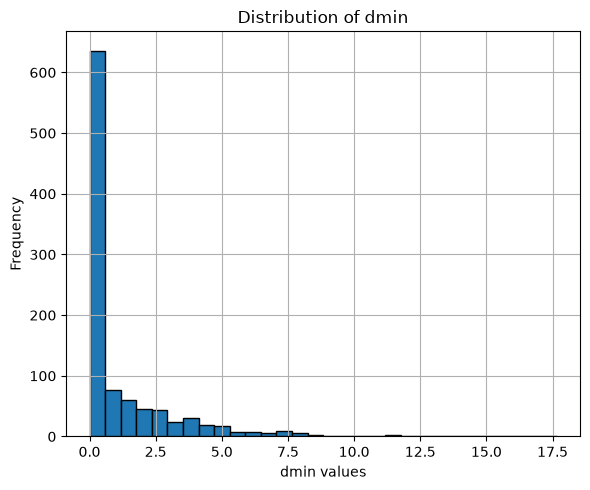

In [102]:
# Create a figure and a set of subplots for 'dmin'
fig_dmin, ax_dmin = plt.subplots(1, 1, figsize=(6, 5))

# Plot histogram for 'dmin'
df['dmin'].hist(ax=ax_dmin, bins=30, edgecolor='black')
ax_dmin.set_title('Distribution of dmin')
ax_dmin.set_xlabel('dmin values')
ax_dmin.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

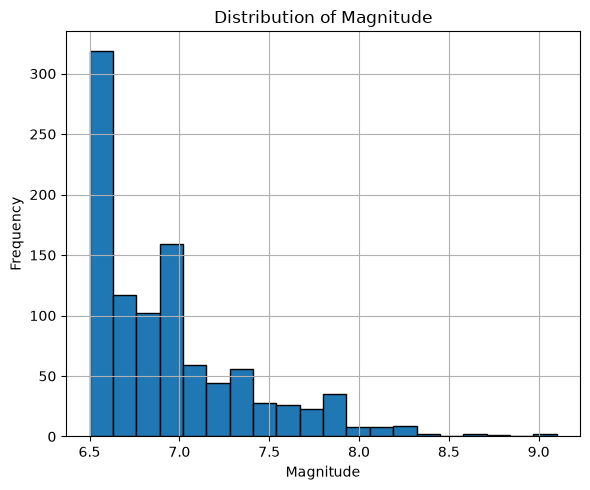

In [103]:
fig_magnitude, ax_magnitude = plt.subplots(1, 1, figsize=(6, 5))

df['magnitude'].hist(ax=ax_magnitude, bins=20, edgecolor='black')
ax_magnitude.set_title('Distribution of Magnitude')
ax_magnitude.set_xlabel('Magnitude')
ax_magnitude.set_ylabel('Frequency')

plt.tight_layout()
plt.show()


* **Gap & Dmin:** The visual histograms perfectly align with our numerical skewness calculations. The vast majority of events occur close to seismic stations (`dmin` near 0) with a low azimuthal gap (`gap` near 0), but the long right tails show rare events occurring far out in the ocean or in unmonitored regions.
* **Magnitude:** The magnitude histogram is also heavily right-skewed. Because the dataset start from magnitude ≥ 6.5, the highest frequency is at the minimum threshold, dropping off rapidly as the magnitude approaches ultra-rare events (8.0+).

## 2e. Correlation Matrix

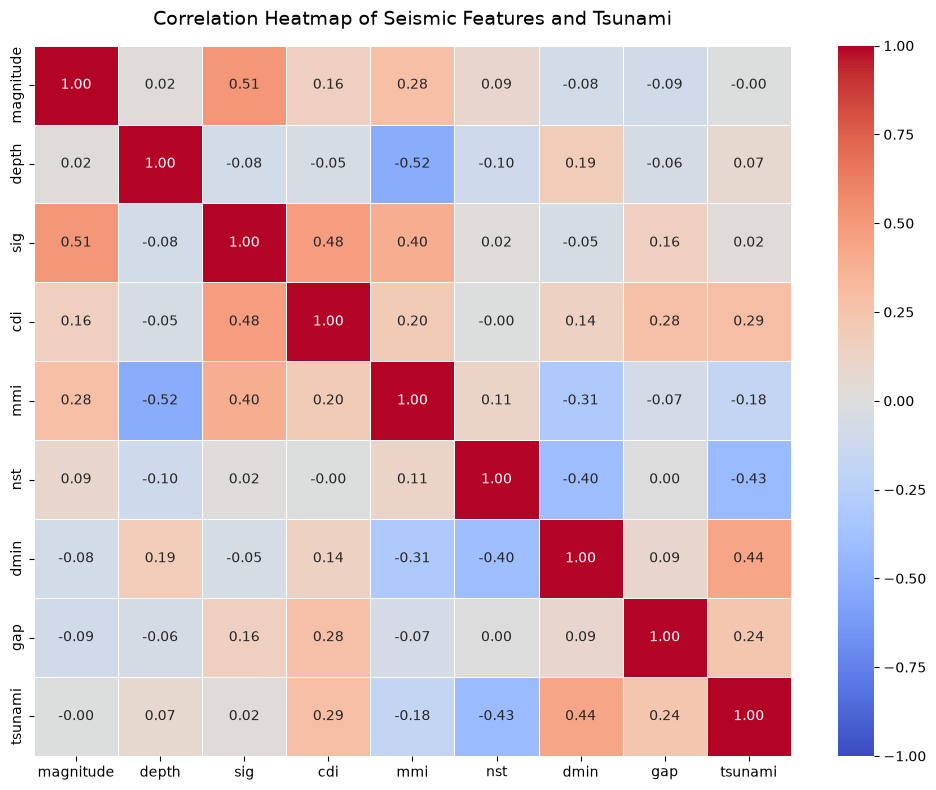

In [104]:
plt.figure(figsize=(10, 8))
# Compute correlation matrix for numeric columns
corr_matrix = df[numeric_cols + ['tsunami']].corr()

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Seismic Features and Tsunami', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

* **Strongest Positive Correlation (`magnitude` vs. `sig`):** There is a strong positive linear relationship between `magnitude` and `sig` (Significance). This is a structural relationship rather than a purely coincidental one: the USGS calculates the `sig` score using a deterministic mathematical formula where the earthquake's objective physical energy (`magnitude`) serves as the core, heavily-weighted input alongside impact factors like injuries and felt reports. Consequently, a higher magnitude automatically guarantees a higher baseline significance score.

* **Strong Positive Correlation (`tsunami` vs. `dmin`):** Earthquakes that triggered tsunamis tend to occur farther from the nearest seismic station. This makes sense because tsunami-generating quakes typically happen offshore in the open ocean, naturally increasing the distance to the nearest land-based monitoring station.

* **Strong Negative Correlation (`tsunami` vs. `nst`):** Earthquakes that triggered tsunamis were recorded by fewer seismic stations. Again, this reflects the remote oceanic location of tsunami-generating quakes — the further out to sea an earthquake occurs, the fewer nearby stations can detect it, resulting in a lower station count.

* **Weak Overall Multicollinearity:** Aside from these expected pairs, the remaining independent features show relatively low linear correlations with one another. This lack of widespread multicollinearity is highly advantageous for machine learning, as it means individual features carry distinct, non-redundant pieces of information.

* Because the features do not share strong, overlapping linear relationships across the board, predicting a complex outcome like a `tsunami` cannot rely on a single dominant feature. The model will need to capture subtle, non-linear feature interactions (such as the combination of a shallow depth *and* a specific faulting mechanism) to make accurate predictions.

## 2f. Boxplot Analysis

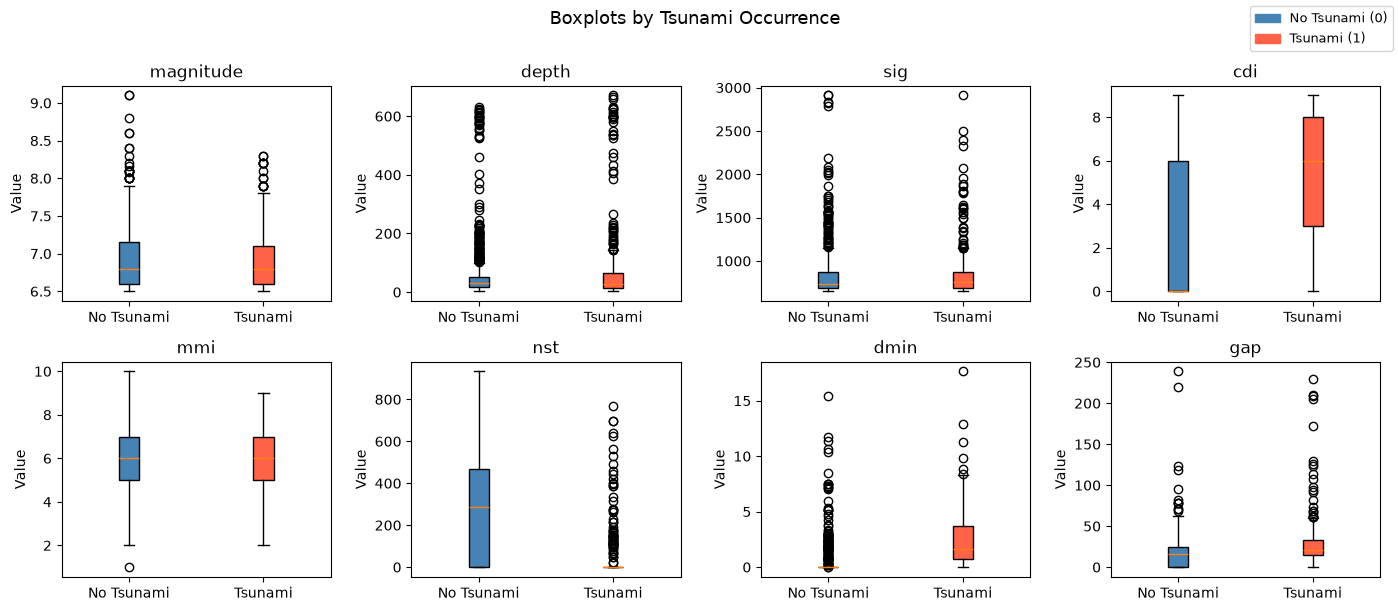

In [105]:
# Boxplots for numeric features — split by tsunami (0 = No, 1 = Yes)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    group0 = df[df['tsunami'] == 0][col].dropna()
    group1 = df[df['tsunami'] == 1][col].dropna()

    bp = axes[i].boxplot([group0, group1],
                         patch_artist=True,
                         tick_labels=['No Tsunami', 'Tsunami'])

    bp['boxes'][0].set_facecolor('steelblue')
    bp['boxes'][1].set_facecolor('tomato')

    axes[i].set_title(col)
    axes[i].set_ylabel('Value')

# Shared legend
from matplotlib.patches import Patch
legend = [Patch(color='steelblue', label='No Tsunami (0)'),
          Patch(color='tomato',    label='Tsunami (1)')]
fig.legend(handles=legend, loc='upper right', fontsize=9)

plt.suptitle('Boxplots by Tsunami Occurrence', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Looking at the boxplots, here are the key observations for each feature:

**`magnitude`, `depth`, `sig`, `mmi`** — For these features, both groups have nearly identical medians and similar spreads. These features alone do not separate tsunami from non-tsunami earthquakes.

**`cdi`** — The Tsunami group has a noticeably higher median and wider box. Earthquakes that triggered tsunamis were more widely felt by people, which is consistent with shallow, near-coast events.

**`nst`** — The No Tsunami group has a much higher median and wider box. This is interesting, more seismic stations recorded non-tsunami quakes, possibly because many tsunami quakes occurred in remote ocean areas with fewer nearby stations.

**`dmin`** — The Tsunami group has a noticeably higher median distance to the nearest station. This again suggests tsunami quakes tend to occur further offshore, away from monitoring stations.

**`gap`** — The Tsunami group has a higher median azimuthal gap, meaning seismic coverage around those quakes was less complete — consistent with remote oceanic locations.

Overall takeaway: The clearest differences between the two groups appear in **`cdi`, `nst`, `dmin, and gap** — all of which relate to location and coverage rather than raw shaking energy. This reinforces the finding from the Point-Biserial correlation that features reflecting where the earthquake occurred matter more than how strong it was.

## 2g. Tsunami Count Pre-2013 vs Post-2013

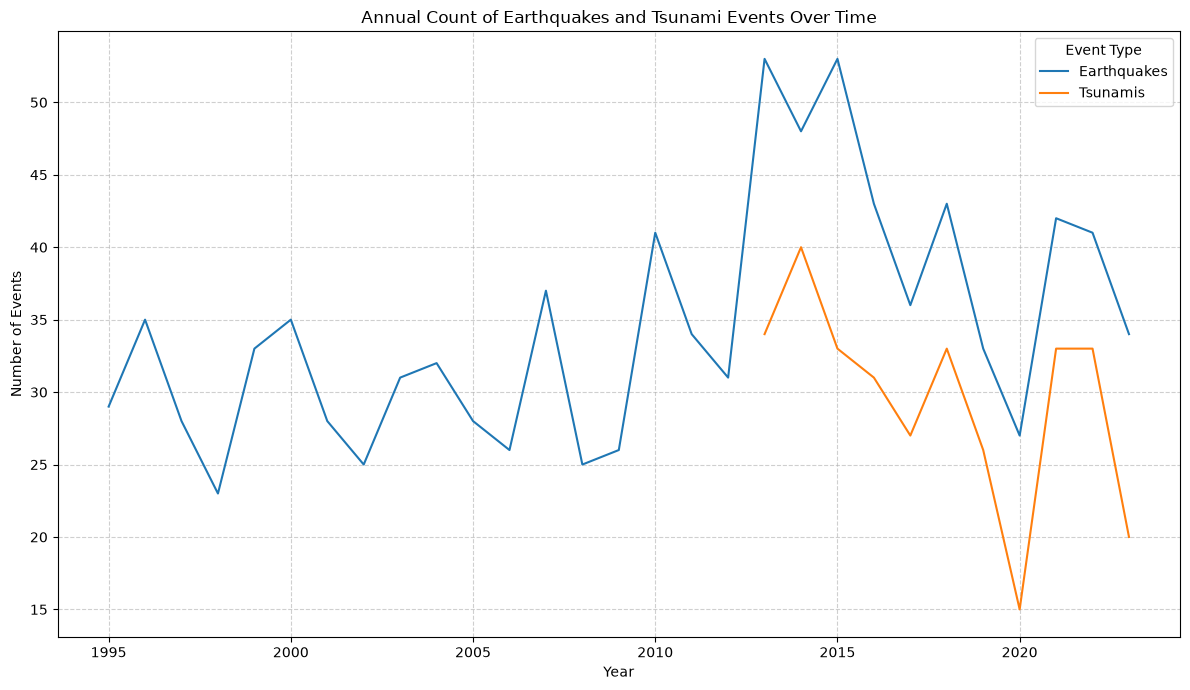

In [106]:
# Calculate annual earthquake counts
earthquake_counts = df.set_index('date_time').resample('YE').size().reset_index(name='count')
earthquake_counts['event_type'] = 'Earthquakes'
earthquake_counts['year'] = earthquake_counts['date_time'].dt.year

# Calculate annual tsunami counts
tsunami_events = df[df['tsunami'] == 1]
tsunami_counts = tsunami_events.set_index('date_time').resample('YE').size().reset_index(name='count')
tsunami_counts['event_type'] = 'Tsunamis'
tsunami_counts['year'] = tsunami_counts['date_time'].dt.year

# Combine the dataframes
combined_counts = pd.concat([earthquake_counts[['year', 'event_type', 'count']], tsunami_counts[['year', 'event_type', 'count']]])

# Create the line chart
plt.figure(figsize=(12, 7))
sns.lineplot(x='year', y='count', hue='event_type', data=combined_counts)
plt.title('Annual Count of Earthquakes and Tsunami Events Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Events')
plt.legend(title='Event Type')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [107]:
# Define the periods
df['period'] = df['year'].apply(lambda x: 'Before 2013' if x < 2013 else '2013 and Forward')

# Group by period and calculate total events and tsunami events
period_summary = df.groupby('period').agg(
    total_events=('year', 'count'),
    tsunami_events=('tsunami', lambda x: (x == 1).sum())
).reset_index()

# Calculate the probability of tsunami occurrence
period_summary['tsunami_probability'] = period_summary['tsunami_events'] / period_summary['total_events']

print("Comparison of Tsunami Occurrence Probability:")
display(period_summary.round(4))

Comparison of Tsunami Occurrence Probability:


,period,total_events,tsunami_events,tsunami_probability
0,2013 and Forward,453,325,0.7174
1,Before 2013,547,0,0.0000


There is no tsunami label for cases before 2013,
could be incorrect tsunami label.
Propose to use data after 2013 only (453 inputs)


**Modelling plan**:
*   Response variable: tsunamim
*   Predictors: magnitude; cdi; mmi; sig; net; nst; dmin; gap; magType; depth; latitude; longitude

## 2h. EDA Summary: Patterns, Insights & Model Selection

**Patterns & Insights Discovered (Updated Research Direction):**
* **Data Quality Issue Identified:** Our time-series analysis comparing events before and after 2013 revealed a glaring anomaly: there are absolutely zero recorded tsunami events prior to 2013. This strongly suggests a systemic labelling issue or a change in data collection protocols rather than a physical reality.
* **Updated Direction:** Because faulty target labels will severely degrade model training, we will subset the data to **only include records from 2013 onwards (453 instances)** for our machine learning phase.

**How EDA Findings Inform Model Selection:**
1. **Scaler Selection:** Our descriptive statistics and distribution analysis revealed that key features (`depth`, `dmin`, `gap`) are heavily right-skewed with significant outliers. Therefore, standardisation using `StandardScaler` is inappropriate. We will use **`RobustScaler`** to scale the data without allowing extreme outliers to skew the distribution.
2. **Handling Class Imbalance:** The target variable is severely imbalanced (roughly 2:1 ratio of no-tsunami to tsunami events). This dictates that we cannot use Accuracy as our primary evaluation metric. We must rely on the **F1-Score** and implement techniques like SMOTE or Balanced Class Weights to penalise the model for ignoring the minority class.
3. **Algorithm Suitability:** The correlation heatmap demonstrated a lack of strong linear relationships between predictors. Because the relationships are likely complex and non-linear, distance-based algorithms (like **K-Nearest Neighbors**) or tree-based ensemble models are much better suited for this prediction task than standard linear regression.

# Part 3: Data Preprocessing and Feature Engineering

In [112]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
)
from imblearn.over_sampling import SMOTE, RandomOverSampler


## 3a. Data Filtering -- Post-2013 Only

In [109]:
#Filter Data Based on EDA Insights
df_filtered = df[df['year'] >= 2013].copy()

## 3b. Define XY

In [110]:
print("\nTarget distribution (tsunami):")
print(df_filtered['tsunami'].value_counts())
print(
    f"Class imbalance ratio: "
    f"{df_filtered['tsunami'].value_counts()[0]} (No Tsunami) : "
    f"{df_filtered['tsunami'].value_counts()[1]} (Tsunami)"
)

# Base numeric features (no engineered cols yet — those come in Step 2)
numeric_features = ['magnitude', 'depth', 'sig', 'cdi', 'mmi', 'nst', 'dmin', 'gap',]

X = df_filtered[numeric_features].copy()
y = df_filtered['tsunami'].copy()

print(f"\nFeatures selected : {len(numeric_features)}")
print(f"  Numeric features          : {numeric_features}")
print(f"\nX shape: {X.shape}   y shape: {y.shape}")


Target distribution (tsunami):
tsunami
1    325
0    128
Name: count, dtype: int64
Class imbalance ratio: 128 (No Tsunami) : 325 (Tsunami)

Features selected : 8
  Numeric features          : ['magnitude', 'depth', 'sig', 'cdi', 'mmi', 'nst', 'dmin', 'gap']

X shape: (453, 8)   y shape: (453,)


## 3c. TrainTestSplit

In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,
    stratify     = y,       # keeps same class % in train and test, note that the data is not time series trend
    random_state = 42
)

print(f"Training set   : {X_train.shape[0]} rows")
print(f"Test set       : {X_test.shape[0]} rows")
print(f"\nClass proportions after stratified split:")
print(f"  Train — tsunami rate : {y_train.astype(int).mean():.3f}")
print(f"  Test  — tsunami rate : {y_test.astype(int).mean():.3f}")
print()



Training set   : 362 rows
Test set       : 91 rows

Class proportions after stratified split:
  Train — tsunami rate : 0.718
  Test  — tsunami rate : 0.714



Note: The minor difference between the Train rate (71.8%) and Test rate (71.4%) is mathematically expected. Because the test split contains a small sample size (91 rows), a single row represents ~1.1% of the entire split.  Stratification matched the true population baseline (71.74%) as closely as mathematically possible without splitting whole rows into fractions.

## 3d. Scaling


In [113]:
X_num_train = X_train[numeric_features].copy()
X_num_test  = X_test[numeric_features].copy()

ss  = StandardScaler()
mms = MinMaxScaler(feature_range=(0, 1))
rs  = RobustScaler()

X_ss_train  = ss.fit_transform(X_num_train)
X_mm_train  = mms.fit_transform(X_num_train)
X_rs_train  = rs.fit_transform(X_num_train)

print("--- Comparison of Scalers Across All Numeric Features ---")

for feature_name in numeric_features:
    print(f"\nFeature: '{feature_name}'")
    print(f"{'Scaler':<20} {'min':>8} {'max':>8} {'mean':>8} {'std':>8}")
    print("-" * 55)

    # Get the column index for the current feature
    col_idx = features.index(feature_name)

    for name, arr in [("StandardScaler", X_ss_train),
                      ("MinMaxScaler",   X_mm_train),
                      ("RobustScaler",   X_rs_train)]:
        # Extract the specific feature's column from the scaled matrix
        col = arr[:, col_idx]
        print(f"{name:<20} {col.min():>8.2f} {col.max():>8.2f} "
              f"{col.mean():>8.2f} {col.std():>8.2f}")

print("\nVerdict: RobustScaler chosen — handles right-skewed features and extreme outliers safely.")

--- Comparison of Scalers Across All Numeric Features ---

Feature: 'magnitude'
Scaler                    min      max     mean      std
-------------------------------------------------------
StandardScaler          -0.99     3.50     0.00     1.00
MinMaxScaler             0.00     1.00     0.22     0.22
RobustScaler            -0.60     3.00     0.20     0.80

Feature: 'depth'
Scaler                    min      max     mean      std
-------------------------------------------------------
StandardScaler          -1.07     7.84    -0.00     1.00
MinMaxScaler             0.00     1.00     0.12     0.11
RobustScaler            -1.33    13.93     0.50     1.71

Feature: 'sig'
Scaler                    min      max     mean      std
-------------------------------------------------------
StandardScaler          -1.72     1.30     0.00     1.00
MinMaxScaler             0.00     1.00     0.57     0.33
RobustScaler            -1.20     0.60    -0.18     0.60

Feature: 'cdi'
Scaler            

## 3e. Class Imbalance

In [114]:
counts = y_train.value_counts()
total  = len(y_train)
print(f"\nClass 0 (no tsunami)  : {counts[0]:>4}  ({counts[0]/total*100:.1f}%)")
print(f"Class 1 (tsunami)     : {counts[1]:>4}  ({counts[1]/total*100:.1f}%)")
print(f"Imbalance ratio       : {counts[0]/counts[1]:.1f} : 1\n")

# Scaled arrays for this section (rs already fit on train)
X_tr_sc = rs.fit_transform(X_train[numeric_features])
X_te_sc = rs.transform(X_test[numeric_features])

results = {}

# --- Baseline ---
# We use standard Logistic Regression without touching weights
lr_base = LogisticRegression(max_iter=1000, random_state=42)
lr_base.fit(X_tr_sc, y_train)
y_pred_base = lr_base.predict(X_te_sc)
results['Baseline (no handling)'] = {
    'acc': accuracy_score(y_test, y_pred_base),
    'f1':  f1_score(y_test, y_pred_base, average='macro', zero_division=0),
}

# --- class_weight='balanced' (Logistic Regression) ---
lr_bal = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_bal.fit(X_tr_sc, y_train)
y_pred_bal = lr_bal.predict(X_te_sc)
results['class_weight=balanced'] = {
    'acc': accuracy_score(y_test, y_pred_bal),
    'f1':  f1_score(y_test, y_pred_bal, average='macro', zero_division=0),
}

# --- Random Oversampling ---
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_tr_sc, y_train)
knn_ros = KNeighborsClassifier(n_neighbors=5)
knn_ros.fit(X_ros, y_ros)
y_pred_ros = knn_ros.predict(X_te_sc)
results['Random oversampling'] = {
    'acc': accuracy_score(y_test, y_pred_ros),
    'f1':  f1_score(y_test, y_pred_ros, average='macro', zero_division=0),
}
print(f"Random oversampling: class 1 grew from {counts[1]} → {(y_ros==1).sum()}")

# --- SMOTE ---
k_smote = min(5, counts[1] - 1)
smote   = SMOTE(k_neighbors=k_smote, random_state=42)
X_smote, y_smote = smote.fit_resample(X_tr_sc, y_train)
knn_smote = KNeighborsClassifier(n_neighbors=5)
knn_smote.fit(X_smote, y_smote)
y_pred_smote = knn_smote.predict(X_te_sc)
results['SMOTE'] = {
    'acc': accuracy_score(y_test, y_pred_smote),
    'f1':  f1_score(y_test, y_pred_smote, average='macro', zero_division=0),
}
print(f"SMOTE: {len(y_train)} samples → {len(y_smote)} synthetic samples")

print(f"\n{'Method':<30} {'Accuracy':>10} {'F1 Score':>10}")
print("-" * 55)
for method, scores in results.items():
    print(f"{method:<30} {scores['acc']:>10.3f} {scores['f1']:>10.3f}")

print(
    "\nKey insight: Macro F1 score  is used because it treats the minority class (No Tsunami) and majority class (Tsunami) exactly equally, it prevents the majority class from inflating overall score as both class accuracy is important in real life. "
    "\nThe baseline model outperforms all balancing techniques. Empirical testing revealed that synthetic oversampling (SMOTE) and class weighting degraded the Macro F1-score from 0.610 to ~0.51-0.58. "
    "\nBecause the baseline model generalised better without artificial manipulation, we opted to proceed with no imbalance handling."
)


Class 0 (no tsunami)  :  102  (28.2%)
Class 1 (tsunami)     :  260  (71.8%)
Imbalance ratio       : 0.4 : 1

Random oversampling: class 1 grew from 260 → 260
SMOTE: 362 samples → 520 synthetic samples

Method                           Accuracy   F1 Score
-------------------------------------------------------
Baseline (no handling)              0.747      0.610
class_weight=balanced               0.637      0.586
Random oversampling                 0.549      0.509
SMOTE                               0.560      0.518

Key insight: Macro F1 score  is used because it treats the minority class (No Tsunami) and majority class (Tsunami) exactly equally, it prevents the majority class from inflating overall score as both class accuracy is important in real life. 
The baseline model outperforms all balancing techniques. Empirical testing revealed that synthetic oversampling (SMOTE) and class weighting degraded the Macro F1-score from 0.610 to ~0.51-0.58. 
Because the baseline model generalis

## 3f. Sklearn Pipeline & Column Transformer

In [115]:
# --- Sub-pipeline: numeric columns ---
numeric_pipe = Pipeline([
    ('scaler',  RobustScaler()),                     # robust to depth outliers
])

# --- ColumnTransformer ---
transformers = [('numeric', numeric_pipe, numeric_features)]

preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

# --- Full pipeline: preprocessor + classifier (BASELINE, NO HANDLING) ---
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier',  LogisticRegression(max_iter=1000, random_state=42)),
])

print("✅ Final pipeline built:")
print("   preprocessor (scale) → Logistic Regression (Baseline)\n")

# --- Train ---
full_pipeline.fit(X_train, y_train)

# --- Evaluate on held-out test set ---
y_pred_pipe = full_pipeline.predict(X_test)

acc_pipe = accuracy_score(y_test, y_pred_pipe)
f1_pipe  = f1_score(y_test, y_pred_pipe, average='macro', zero_division=0)

print(f"Pipeline results on test set:")
print(f"  Accuracy : {acc_pipe:.3f}")
print(f"  F1 Score : {f1_pipe:.3f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred_pipe,
    target_names=['No Tsunami', 'Tsunami'],
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred_pipe)
print("Confusion matrix:")
print(f"  True Negative  (correctly predicted NO Tsunami) : {cm[0][0]}")
print(f"  False Positive (false alarm)                    : {cm[0][1]}")
print(f"  False Negative (MISSED a real Tsunami) ⚠️        : {cm[1][0]}")
print(f"  True Positive  (correctly predicted Tsunami)    : {cm[1][1]}")

✅ Final pipeline built:
   preprocessor (scale) → Logistic Regression (Baseline)

Pipeline results on test set:
  Accuracy : 0.747
  F1 Score : 0.610

Classification report:
              precision    recall  f1-score   support

  No Tsunami       0.64      0.27      0.38        26
     Tsunami       0.76      0.94      0.84        65

    accuracy                           0.75        91
   macro avg       0.70      0.60      0.61        91
weighted avg       0.73      0.75      0.71        91

Confusion matrix:
  True Negative  (correctly predicted NO Tsunami) : 7
  False Positive (false alarm)                    : 19
  False Negative (MISSED a real Tsunami) ⚠️        : 4
  True Positive  (correctly predicted Tsunami)    : 61


## 3g. Cross-validation

In [116]:
skf    = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(full_pipeline, X_train, y_train, cv=skf, scoring='accuracy')
cv_f1  = cross_val_score(full_pipeline, X_train, y_train, cv=skf, scoring='f1_macro')

print(f"\nAccuracy per fold : {[round(v, 3) for v in cv_acc]}")
print(f"Accuracy mean     : {cv_acc.mean():.3f} ± {cv_acc.std():.3f}")
print(f"\nF1 per fold       : {[round(v, 3) for v in cv_f1]}")
print(f"F1 mean           : {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")
print(
    "\nInterpretation: The model demonstrated reasonable stability, with test set performance (F1 = 0.610) falling within the expected variance of the 5-fold cross-validation scores (F1 = 0.570 ± 0.058)."
    "\nSame goes with the accuracy. The overall alignment between CV and test metrics indicates the model generalized without severe overfitting."
)


Accuracy per fold : [np.float64(0.726), np.float64(0.685), np.float64(0.75), np.float64(0.736), np.float64(0.764)]
Accuracy mean     : 0.732 ± 0.027

F1 per fold       : [np.float64(0.558), np.float64(0.529), np.float64(0.517), np.float64(0.567), np.float64(0.679)]
F1 mean           : 0.570 ± 0.058

Interpretation: The model demonstrated reasonable stability, with test set performance (F1 = 0.610) falling within the expected variance of the 5-fold cross-validation scores (F1 = 0.570 ± 0.058).
Same goes with the accuracy. The overall alignment between CV and test metrics indicates the model generalized without severe overfitting.


## 3h. Compiled Preprocessing Pipeline

In [117]:
# Preprocessor-Only Pipeline (For Inspection Only)
preprocess_only = Pipeline([('preprocessor', preprocessor)])

X_train_preprocessed = preprocess_only.fit_transform(X_train)
X_test_preprocessed  = preprocess_only.transform(X_test)

print(f"X_train_preprocessed shape : {X_train_preprocessed.shape}")
print(f"X_test_preprocessed shape  : {X_test_preprocessed.shape}")

X_train_preprocessed shape : (362, 8)
X_test_preprocessed shape  : (91, 8)


# Part 4: Model Fitting

In [118]:
# Fit all models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)


class ModelSelector:

    def __init__(self, x_train, x_test, y_train, y_test, features=None):
        self.x_train = x_train
        self.x_test = x_test
        self.y_train = y_train
        self.y_test = y_test
        self.features = features

        self.cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        self.scoring_metric = "f1_macro"
        self.best_models = {}
        self.results = []

        self.best_model_name = None
        self.best_model = None
        self.results_df = None

    def define_models(self):

        self.models = {

            "Logistic Regression": {
                "estimator": Pipeline([
                    ("scaler", RobustScaler()),
                    ("model", LogisticRegression(
                        max_iter=1000,
                        class_weight="balanced",
                        solver="lbfgs",
                        random_state=42
                    ))
                ]),
                "param_grid": {
                    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
                }
            },

            "KNN": {
                "estimator": Pipeline([
                    ("scaler", RobustScaler()),
                    ("model", KNeighborsClassifier())
                ]),
                "param_grid": {
                    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
                    "model__weights": ["uniform", "distance"]
                }
            },

            "Decision Tree": {
                "estimator": DecisionTreeClassifier(
                    random_state=42
                ),
                "param_grid": {
                    "criterion": ["gini", "entropy"],
                    "max_depth": [None, 3, 5],
                    "min_samples_split": [10, 20],
                    "min_samples_leaf": [5, 10]
                }
            },

            "Random Forest": {
                "estimator": RandomForestClassifier(
                    random_state=42,
                    n_jobs=-1,
                    bootstrap=True,
                    oob_score=True
                ),
                "param_grid": {
                    "n_estimators": [100, 200],
                    "criterion": ["gini", "entropy"],
                    "max_depth": [2, 3],
                    "min_samples_split": [10, 20],
                    "min_samples_leaf": [5, 10],
                    "max_features": ["sqrt", "log2"],
                    "class_weight": [None, "balanced"]
                }
            },

            "Gradient Boosting": {
                "estimator": GradientBoostingClassifier(
                    random_state=42
                ),
                "param_grid": {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.01, 0.1, 0.2],
                    "max_depth": [2, 3],
                    "subsample": [0.8, 1.0]
                }
            },

            "Naive Bayes": {
                "estimator": GaussianNB(),
                "param_grid": {
                    "var_smoothing": [1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
                }
            },

            "SVM": {
                "estimator": Pipeline([
                    ("scaler", RobustScaler()),
                    ("model", SVC(
                        random_state=42
                    ))
                ]),
                "param_grid": {
                    "model__C": [0.1, 1, 10, 100],
                    "model__kernel": ["linear", "rbf"],
                    "model__gamma": ["scale", "auto"],
                    "model__class_weight": [None, "balanced"]
                }
            }
        }

    def train_one_model(self, model_name, model_info):

        print("\n" + "=" * 70)
        print(f"Training model: {model_name}")
        print("=" * 70)

        grid = GridSearchCV(
            estimator=model_info["estimator"],
            param_grid=model_info["param_grid"],
            cv=self.cv,
            scoring=self.scoring_metric,
            n_jobs=-1,
            error_score="raise"
        )

        grid.fit(self.x_train, self.y_train)

        y_pred = grid.predict(self.x_test)

        train_score = grid.score(self.x_train, self.y_train)
        test_accuracy = accuracy_score(self.y_test, y_pred)
        test_f1 = f1_score(self.y_test, y_pred, average="macro")
        test_precision = precision_score(
            self.y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
        test_recall = recall_score(
            self.y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        print("Best params:", grid.best_params_)
        print("Best CV score:", grid.best_score_)
        print("Training F1 macro:", train_score)
        print("Test accuracy:", test_accuracy)
        print("Test F1 macro:", test_f1)

        print("\nConfusion Matrix:")
        print(confusion_matrix(self.y_test, y_pred))

        print("\nClassification Report:")
        print(classification_report(self.y_test, y_pred, zero_division=0))

        self.best_models[model_name] = grid.best_estimator_

        self.results.append({
            "Model": model_name,
            "Best CV F1 Macro": grid.best_score_,
            "Training F1 Macro": train_score,
            "Test Accuracy": test_accuracy,
            "Test F1 Macro": test_f1,
            "Test Precision Macro": test_precision,
            "Test Recall Macro": test_recall,
            "Best Params": grid.best_params_
        })

    def train_all_models(self):

        self.define_models()

        for model_name, model_info in self.models.items():
            self.train_one_model(model_name, model_info)

    def compare_models(self):

        self.results_df = pd.DataFrame(self.results)

        self.results_df = self.results_df.sort_values(
            by="Test F1 Macro",
            ascending=False
        )

        print("\n" + "=" * 70)
        print("FINAL MODEL COMPARISON")
        print("=" * 70)
        print(self.results_df)

        self.best_model_name = self.results_df.iloc[0]["Model"]
        self.best_model = self.best_models[self.best_model_name]

        print("\nBest Overall Model:", self.best_model_name)
        print("Best Model:")
        print(self.best_model)

        return self.results_df

    def save_results(self, filename="model_comparison_results.csv"):

        if self.results_df is not None:
            self.results_df.to_csv(filename, index=False)
            print(f"\nModel comparison results saved to: {filename}")
        else:
            print("\nNo results found. Please run compare_models() first.")

    def save_best_model(self, filename="best_classification_model.pkl"):

        if self.best_model is not None:
            with open(filename, "wb") as f:
                pickle.dump(self.best_model, f)
                print(f"\nBest model saved to: {filename}")
        else:
            print("\nNo best model found. Please run compare_models() first.")

In [119]:
# Select the best model
Selector = ModelSelector(
    x_test= X_test_preprocessed,
    x_train= X_train_preprocessed,
    y_train= y_train,
    y_test = y_test,
    features = features
)

Selector.train_all_models()

results_df = Selector.compare_models()
Selector.save_best_model("best_model.pkl")


Training model: Logistic Regression
Best params: {'model__C': 0.1}
Best CV score: 0.6642012026535138
Training F1 macro: 0.6700759493670886
Test accuracy: 0.6593406593406593
Test F1 macro: 0.6040701754385964

Confusion Matrix:
[[13 13]
 [18 47]]

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.50      0.46        26
           1       0.78      0.72      0.75        65

    accuracy                           0.66        91
   macro avg       0.60      0.61      0.60        91
weighted avg       0.68      0.66      0.67        91


Training model: KNN
Best params: {'model__n_neighbors': 9, 'model__weights': 'distance'}
Best CV score: 0.6093835051729789
Training F1 macro: 1.0
Test accuracy: 0.7252747252747253
Test F1 macro: 0.5578231292517006

Confusion Matrix:
[[ 5 21]
 [ 4 61]]

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.19      0.29        26
           1     

## 4a. Confusion Matrix for training set of the best model

In [120]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_rf = RandomForestClassifier(
    class_weight='balanced',
    max_depth=3,
    min_samples_leaf=10,
    min_samples_split=10,
    n_jobs=-1,
    random_state=42
)

# 1. Explicitly fit the model to your training data
best_rf.fit(X_train_preprocessed, y_train)

# 2. Predict on the training data
y_train_pred = best_rf.predict(X_train_preprocessed)

# 3. Generate and plot the training confusion matrix
print("---Confusion Matrix of training set---")
print(confusion_matrix(y_train, y_train_pred))


---Confusion Matrix of training set---
[[ 81  21]
 [ 57 203]]


## 4b. Cross Validation Inspection

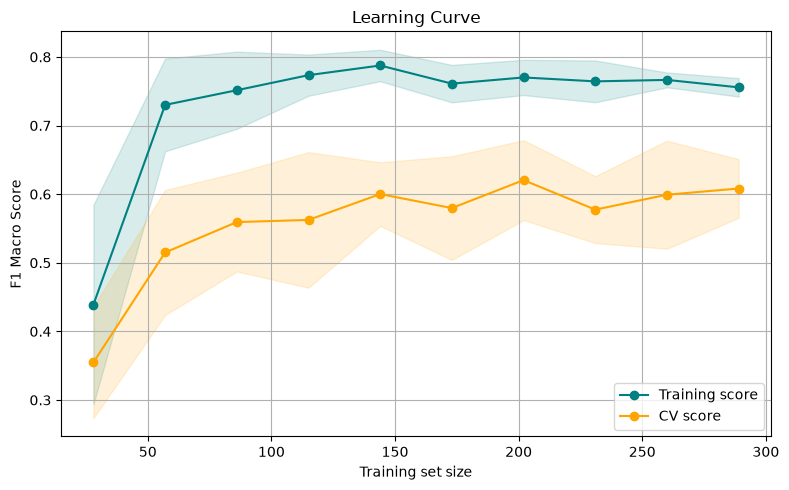

In [121]:
from sklearn.model_selection import learning_curve, validation_curve

# ==========================================
# Plot 1: Learning Curve
# ==========================================
train_sizes, train_scores, cv_scores = learning_curve(
    estimator=best_rf,
    X=X_train_preprocessed,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring='f1_macro',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
cv_mean    = cv_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
cv_std     = cv_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', color='teal', label='Training score')
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15, color='teal')
plt.plot(train_sizes, cv_mean, 'o-', color='orange', label='CV score')
plt.fill_between(train_sizes, cv_mean-cv_std, cv_mean+cv_std, alpha=0.15, color='orange')
plt.xlabel('Training set size'); plt.ylabel('F1 Macro Score')
plt.title('Learning Curve'); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()




Train: Train score: high → ~0.75

CV:    CV score: close to train and converging → ~0.63

Diagnosis: Model is well-fitted. Generalises
well. More data gives diminishing returns.

Gap: Small acceptable gap both lines converge at a good
score